In [14]:
from google.colab import files
uploaded = files.upload()

Saving EEG(alpha).csv to EEG(alpha) (2).csv
Saving EEG(delta).csv to EEG(delta) (2).csv
Saving EEG(theta).csv to EEG(theta) (2).csv
Saving EEG(beta).csv to EEG(beta) (2).csv


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.signal import welch

alpha = pd.read_csv('EEG(alpha).csv')
beta  = pd.read_csv('EEG(beta).csv')
delta = pd.read_csv('EEG(delta).csv')
theta = pd.read_csv('EEG(theta).csv')

alpha_sig = alpha.iloc[:,1].values
beta_sig  = beta.iloc[:,1].values
delta_sig = delta.iloc[:,1].values
theta_sig = theta.iloc[:,1].values

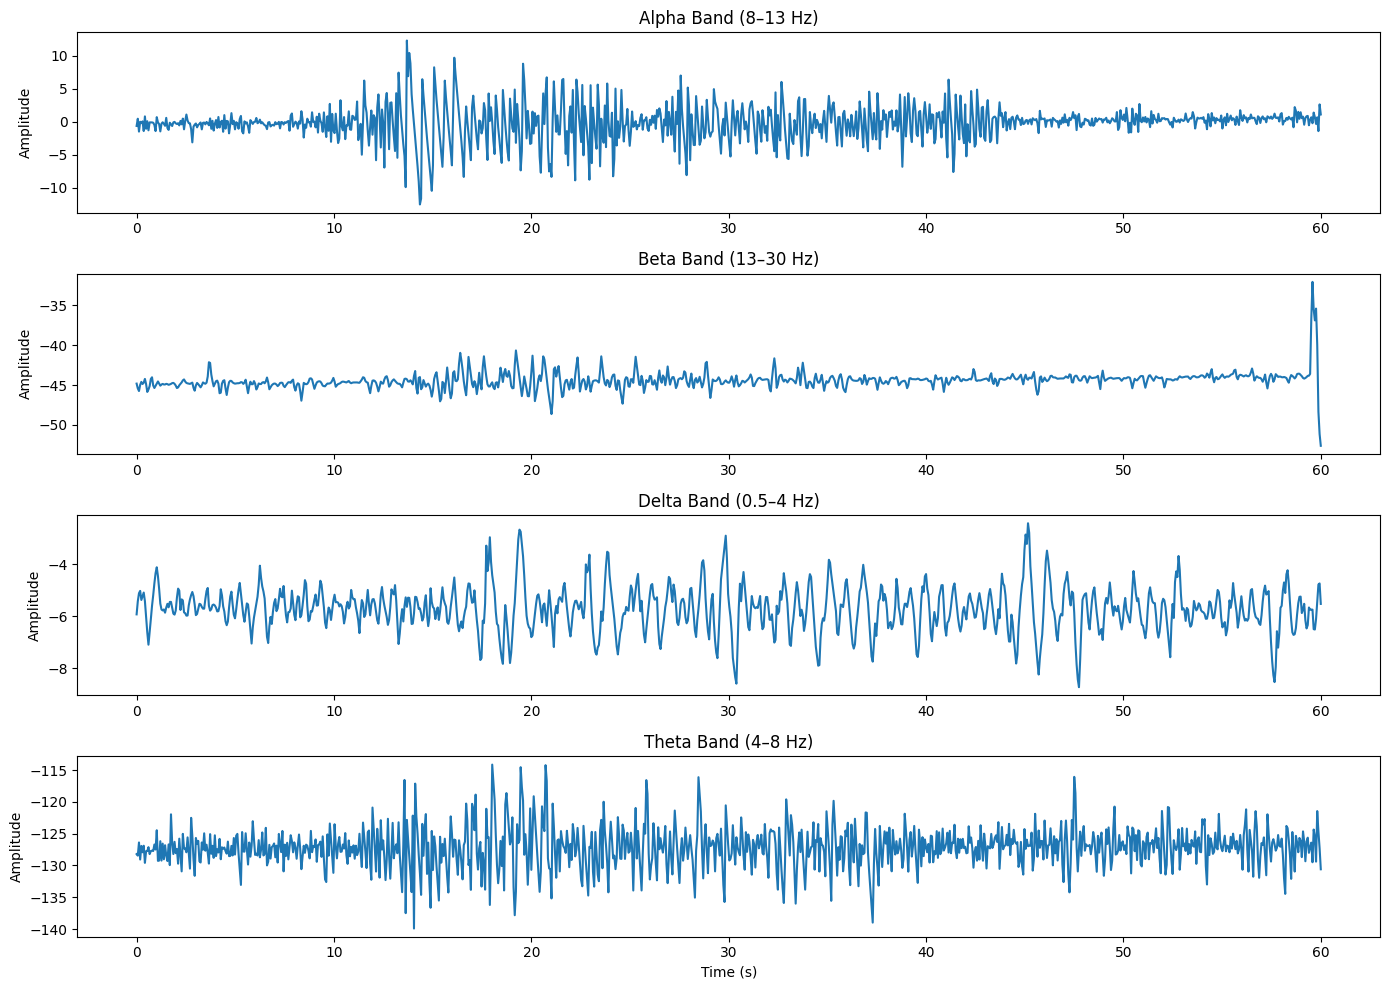

In [16]:
time_common = np.linspace(0, 60, 1000)

def resample(signal):
    t_old = np.linspace(0, 60, len(signal))
    f = interp1d(t_old, signal, kind='linear')
    return f(time_common)

alpha_r = resample(alpha_sig)
beta_r  = resample(beta_sig)
delta_r = resample(delta_sig)
theta_r = resample(theta_sig)
plt.figure(figsize=(14,10))

plt.subplot(4,1,1)
plt.plot(time_common, alpha_r)
plt.title("Alpha Band (8–13 Hz)")
plt.ylabel("Amplitude")

plt.subplot(4,1,2)
plt.plot(time_common, beta_r)
plt.title("Beta Band (13–30 Hz)")
plt.ylabel("Amplitude")

plt.subplot(4,1,3)
plt.plot(time_common, delta_r)
plt.title("Delta Band (0.5–4 Hz)")
plt.ylabel("Amplitude")

plt.subplot(4,1,4)
plt.plot(time_common, theta_r)
plt.title("Theta Band (4–8 Hz)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [17]:
def compute_snr(signal, band_low, band_high, fs):
    f, Pxx = welch(signal, fs, nperseg=256)

    band_power = np.sum(Pxx[(f >= band_low) & (f <= band_high)])
    noise_power = np.sum(Pxx) - band_power

    return 10 * np.log10(band_power / noise_power)

# Correct sampling frequency
fs = len(time_common) / (time_common[-1] - time_common[0])

print("Sampling Frequency:", fs)

snr_alpha = compute_snr(alpha_r, 8, 13, fs)
snr_beta  = compute_snr(beta_r, 13, 30, fs)
snr_delta = compute_snr(delta_r, 0.5, 4, fs)
snr_theta = compute_snr(theta_r, 4, 8, fs)

print("SNR (dB):")
print("Alpha:", snr_alpha)
print("Beta :", snr_beta)
print("Delta:", snr_delta)
print("Theta:", snr_theta)

Sampling Frequency: 16.666666666666668
SNR (dB):
Alpha: -18.055698684598365
Beta : -inf
Delta: 12.02812236888985
Theta: -2.1776967579859017


/tmp/ipykernel_5203/2816275464.py:7: RuntimeWarning: divide by zero encountered in log10
  return 10 * np.log10(band_power / noise_power)


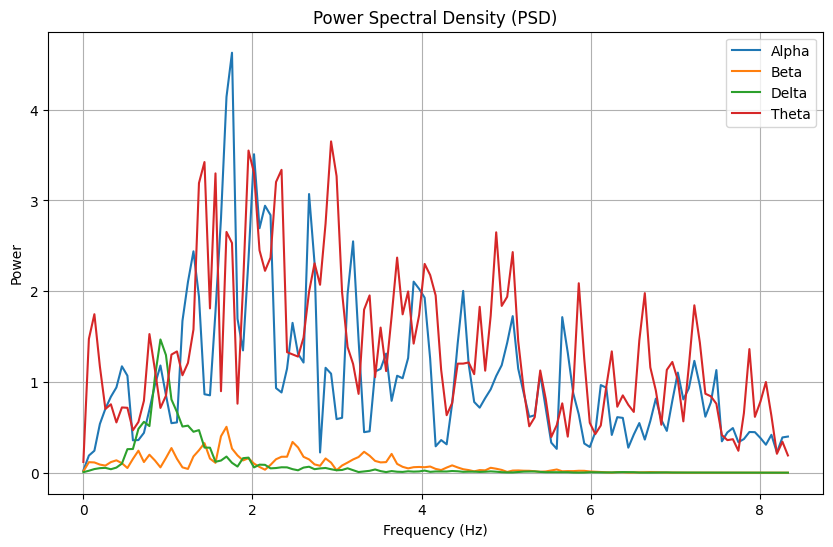

In [18]:
plt.figure(figsize=(10,6))

for signal, label in zip(
    [alpha_r, beta_r, delta_r, theta_r],
    ["Alpha", "Beta", "Delta", "Theta"]
):
    f, Pxx = welch(signal, fs, nperseg=256)
    plt.plot(f, Pxx, label=label)

plt.title("Power Spectral Density (PSD)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power")
plt.legend()
plt.grid()
plt.show()

In [19]:
def band_power(signal):
    return np.mean(signal**2)

print("Band Power:")
print("Alpha:", band_power(alpha_r))
print("Beta :", band_power(beta_r))
print("Delta:", band_power(delta_r))
print("Theta:", band_power(theta_r))

Band Power:
Alpha: 6.894105090418243
Beta : 1972.9219558589332
Delta: 33.16856975635518
Theta: 16179.794742483668
